<a href="https://colab.research.google.com/github/kinjaljoshi/mech-interp-from-scratch/blob/master/gpt2_embedding_geometry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install transformer_lens

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 60.8 MB/s  0:00:00
  Created wheel for transformers-stream-generator: filename=transformers_stream_generator-0.0.5-py3-none-any.whl size=12526 sha256=499ce575bd0cb3ab6ce1ba77ac125a252fe3a74ae1bac92a82367bf01af095b1
  Stored in directory: /root/.cache/pip/wheels/f6/6e/1a/710143d0e50e827ae5b60a47a6d43d715cf1c6e35881a05530
Successfully built transformers-stream-generator
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [transformer_lens]


In [2]:
import torch, math
from transformer_lens import TransformerBridge

model = TransformerBridge.boot_transformers("gpt2")
model.enable_compatibility_mode()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [3]:
W_E = model.W_E.detach().cpu()

N, d = W_E.shape

print(f"vocab size: {N} embedding dim: {d} ")

idx = torch.randperm(N)[:3000]

def offdiag_interf(X):
  Xn = X / X.norm(dim =1, keepdim = True)
  C = Xn @ Xn.T
  return C[~torch.eye(len(X), dtype= torch.bool)]

offdiag_interf(W_E[idx])


vocab size: 50257 embedding dim: 768 


tensor([0.2142, 0.5664, 0.3544,  ..., 0.2606, 0.3520, 0.2415])

In [5]:
sets = {
    "Real (Raw W_E)":               offdiag_interf(W_E[idx]),
    "Real, Mean Removed": offdiag_interf((W_E - W_E.mean(0))[idx]),
    "Random Gaussian":    offdiag_interf(torch.randn(3000, d)),
}
for name, c in sets.items():
    print(f"{name:20s} mean={c.mean():+.3f}  std={c.std():.3f}  "
          f"frac |cos|>0.3: {(c.abs() > 0.3).float().mean():.4%}")
print("1/sqrt(d) =", round(1 / math.sqrt(d), 3))

norms = W_E.norm(dim=1)
print(f"token norms: mean={norms.mean():.2f} min={norms.min():.2f} max={norms.max():.2f}")

Real (Raw W_E)       mean=+0.268  std=0.053  frac |cos|>0.3: 25.5125%
Real, Mean Removed   mean=+0.000  std=0.049  frac |cos|>0.3: 0.0481%
Random Gaussian      mean=+0.000  std=0.036  frac |cos|>0.3: 0.0000%
1/sqrt(d) = 0.036
token norms: mean=3.96 min=2.45 max=6.31



#Token Embeddings are a "Clean Slate"

In machine learning, superposition is the trick a model uses to pack more features into a space than it has dimensions (like packing 3 features into 2 dimensions by forming a Y-shape). If tokens were using superposition, we would see pairs of vectors structurally crammed together at high angles (like cosine similarities of 0.3, 0.5, or higher), even after removing the mean.
Because the percentage of pairs with |cos| > 0.3\) drops to exactly 0.0000% after removing the mean, it implies that GPT-2 goes out of its way to ensure no two tokens accidentally overlap. The model treats every word in its vocabulary as an independent, isolated starting point.

Generating annotated plot...
Displaying plot...


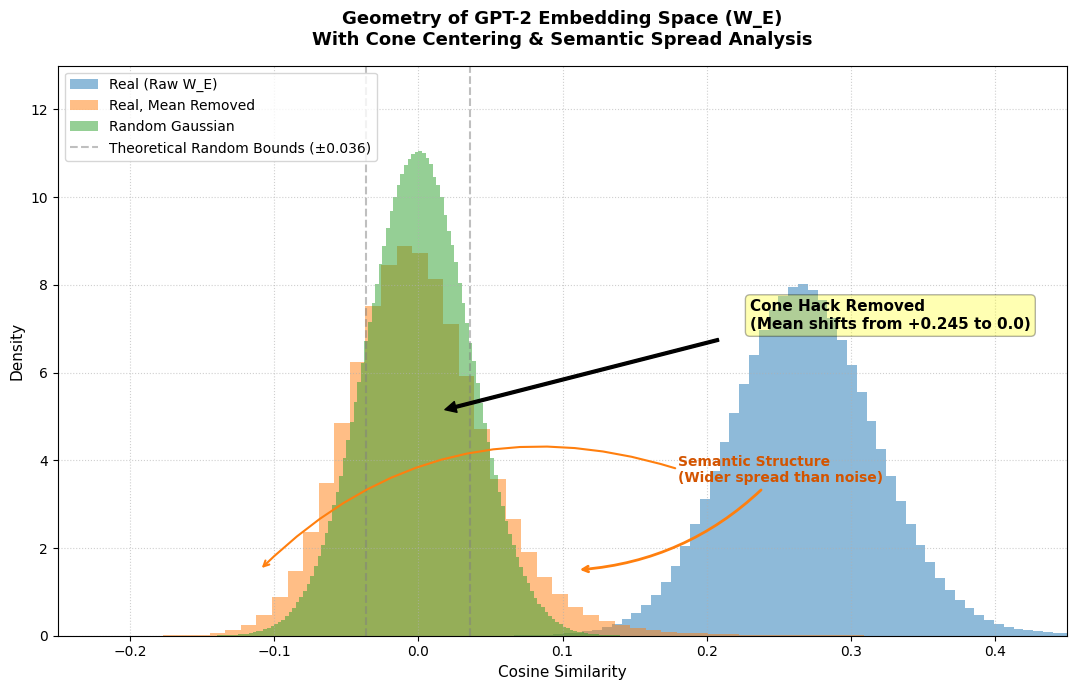

In [6]:
import matplotlib.pyplot as plt

# --- Plotting Code with Arrow Annotations ---
print("Generating annotated plot...")
plt.figure(figsize=(11, 7))

colors = {"Real (Raw W_E)": "#1f77b4", "Real, Mean Removed": "#ff7f0e", "Random Gaussian": "#2ca02c"}

for name, c in sets.items():
    plt.hist(c.numpy(), bins=150, density=True, alpha=0.5, label=name, color=colors[name])

# Add vertical dashed lines for theoretical limits of noise
theoretical_std = 1 / math.sqrt(d)
plt.axvline(x=theoretical_std, color="gray", linestyle="--", alpha=0.5)
plt.axvline(x=-theoretical_std, color="gray", linestyle="--", alpha=0.5,
            label=f"Theoretical Random Bounds (±{theoretical_std:.3f})")

# 1: The Mean Shift (Cone Removal)
# This arrow shows the massive shift from the raw cone center down to the 0.0 center
plt.annotate(
    "Cone Hack Removed\n(Mean shifts from +0.245 to 0.0)",
    xy=(0.0, 5),          # Arrow points here (centered distribution)
    xytext=(0.23, 7),     # Text originates here (near the raw distribution peak)
    arrowprops=dict(facecolor='black', shrink=0.08, width=2, headwidth=8, headlength=8),
    fontsize=11, fontweight='bold', color='black', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3)
)

# 2 & 3: Semantic Widening Arrows
# These arrows draw attention to the wide wings of the orange distribution, showing semantic structure
plt.annotate(
    "Semantic Structure\n(Wider spread than noise)",
    xy=(0.11, 1.5),       # Arrow points to the right tail of the orange distribution
    xytext=(0.18, 3.5),   # Text location
    arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=2, connectionstyle="arc3,rad=-0.2"),
    fontsize=10, color='#d35400', fontweight='bold'
)

plt.annotate(
    "",
    xy=(-0.11, 1.5),      # Arrow points to the left tail of the orange distribution
    xytext=(0.18, 3.8),   # Connects back up near the same text block
    arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.5, connectionstyle="arc3,rad=0.3")
)

# Visual Customization
plt.title("Geometry of GPT-2 Embedding Space (W_E)\nWith Cone Centering & Semantic Spread Analysis", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Cosine Similarity", fontsize=11)
plt.ylabel("Density", fontsize=11)
plt.xlim(-0.25, 0.45)
plt.ylim(0, 13)  # Leave room at the top for labels and annotations
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=10, loc="upper left")

plt.tight_layout()
print("Displaying plot...")
plt.show()


#Which tokens share directions


Neighbors in embedding space. A higher-than-random cosine spread means some tokens sit close together. We check two things: (a) which tokens are nearest neighbors of a few probe tokens, to see whether the overlap is semantic, spelling-based, or something else, and (b) how large each token’s best match is, versus random vectors. This is the real-model analog of the toy model’s off-diagonal entries of G.

In [4]:
#centrring the matrix
Wc = W_E - W_E.mean(0)

Wn = W_E / Wc.norm(dim=1, keepdim=True)


def nearest_neighbor(tok, k=5):
  ids = model.to_tokens(tok, prepend_bos=False)[0]
  if len(ids) !=1:
    return f"skipping token {tok} | length is {len(ids)}"
  i = ids[0].item()
  sims = Wn @ Wn[i]
  top = sims.topk(k + 1).indices[1:]
  return f"{sims.topk(k + 1).values[1:].round(decimals=2).tolist()} \n {[(model.tokenizer.decode(int(j))) for j in top]}"

for t in [" king", " Paris", " running", " 1999", " the"]:
    print((t), "->", nearest_neighbor(t))

def best_match(X):
  Xn = X / X.norm(dim =1, keepdim =True)
  C = Xn @ Xn.T
  C.fill_diagonal_(-1)
  return C.max(dim =1).values

real_best = best_match(Wc[idx])
print(f"real best mean - {real_best.mean():2f} | real best std- {real_best.std():2f}")
rand_best = best_match(torch.randn(3000, 768))
print(f"real best mean - {rand_best.mean():2f} | real best std- {rand_best.std():2f}")

print(f"real: 90th pct={real_best.quantile(0.9):.3f}  max={real_best.max():.3f}")

 king -> [0.9599999785423279, 0.8199999928474426, 0.8100000023841858, 0.7900000214576721, 0.7900000214576721] 
 [' kings', ' queen', ' King', '\x0b', ' externalToEVA']
 Paris -> [1.1200000047683716, 0.8199999928474426, 0.8100000023841858, 0.8100000023841858, 0.8100000023841858] 
 ['Paris', ' externalToEVA', '�', '\x00', '�']
 running -> [0.8700000047683716, 0.8600000143051147, 0.7799999713897705, 0.7400000095367432, 0.6800000071525574] 
 [' Running', 'Running', 'running', ' ran', ' runs']
 1999 -> [1.2100000381469727, 1.1699999570846558, 1.149999976158142, 1.149999976158142, 1.1100000143051147] 
 [' 1998', ' 1997', ' 1995', '1999', ' 1996']
 the -> [0.6100000143051147, 0.5899999737739563, 0.5899999737739563, 0.5799999833106995, 0.5600000023841858] 
 [' a', ' an', 'The', 'the', ' it']
real best mean - 0.323921 | real best std- 0.131000
real best mean - 0.128041 | real best std- 0.011660
real: 90th pct=0.516  max=0.989


#GPT-2 MLP neurons mean one thing each?


Neuron basis vs. features. In the toy model the hidden space had no privileged axes, since you could rotate it and nothing changed. An MLP layer is different: its nonlinearity acts on each neuron separately, so the neuron axes are special, and a model has a reason to align a feature with a single neuron. Superposition pushes the other way. With more features than neurons, a neuron can end up serving several unrelated features, which is what polysemantic means.

**Two tests.**

1. Basis test (quantitative). Take the neuron activations and rotate them by a random orthogonal matrix. If features line up with neurons, the neuron basis should be sparser (more heavy-tailed, so higher kurtosis) than the rotated one. If features are smeared across neurons, the two should look alike.
2. Reading test (qualitative). Print the top-activating contexts for a few neurons and read them: one theme, or several unrelated ones?

In [5]:
from datasets import load_dataset
from transformer_lens.utilities import tokenize_and_concatenate
from collections import Counter

ds = load_dataset("NeelNanda/pile-10k", split = "train")
all_tokens = tokenize_and_concatenate(ds, model.tokenizer, max_length=128, add_bos_token=True)

README.md:   0%|          | 0.00/373 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/921 [00:00<?, ?B/s]

data/train-00000-of-00001-4746b8785c874c(…): reconstructing file:   0%|          |  0.00B / 33.3MB            

data/train-00000-of-00001-4746b8785c874c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map (num_proc=10):   0%|          | 0/10000 [00:00<?, ? examples/s]

In [6]:
print(model.cfg.device)

cuda


In [7]:
all_toks = torch.tensor(all_tokens[:200]["tokens"])
tokens = all_toks[:, 1:]
#tokens.shape
# tokens = all_tok[:200 , 1:] #selecting 200 records and dropping BOS token
L = 5

hook = f"blocks.{L}.mlp.hook_post"
#print(hook)
acts = []
#logit, cache = model.run_with_cache(tokens[0:50].to(model.cfg.device), names_filter=hook)
#cache
# cache
with torch.no_grad():
  for i in range(0, len(all_toks[:200]), 50):
    logit, cache = model.run_with_cache(all_toks[i:i+50].to(model.cfg.device), names_filter=hook)
    acts.append(cache[hook][:, 1:].cpu())
acts = torch.cat(acts)
acts = acts.reshape(-1, acts.shape[-1])

flat_tok = tokens.reshape(-1)

d_mlp = acts.shape[1]
print("activations:", tuple(acts.shape))

/tmp/ipykernel_884/264363578.py:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  all_toks = torch.tensor(all_tokens[:200]["tokens"])


activations: (25400, 3072)


### 🧠 Statistical Detection of "Concept Cells" (MLP Neurons)

This function calculates **Excess Kurtosis** to identify highly sparse, specialized neurons—often referred to as **concept cells**. In mechanistic interpretability, we use this to distinguish between neurons that process generic background noise versus those that act as crisp feature detectors.

#### 📊 Understanding the Kurtosis Score:
* **Score ≈ 0 (Normal Distribution):** The neuron acts like random noise, fluctuating constantly at a steady baseline. It does not detect a specific concept.
* **Score > 0 (Heavy-Tailed / Leptokurtic):** The neuron is highly sparse. It sits dead silent (0) for 99% of tokens, but fires a massive outlier spike when it encounters its exact preferred concept (e.g., a specific Python syntax rule, a geographic location, or a punctuation pattern).

#### 🛠️ Mathematical Step-by-Step:
1. **`X - X.mean(0)` (Centering):** Shifts the data so every neuron averages out to 0, ensuring we measure true deviations rather than absolute baseline volume.
2. **`(X**4).mean(0)` (The Spike Amplifier):** Raising activations to the 4th power heavily exaggerates rare, massive spikes (e.g., $10^4 = 10,000$) while crushing small fluctuations (e.g., $0.1^4 = 0.0001$).
3. **`(X**2).mean(0) ** 2` (Variance Normalization):** Normalizes the score relative to the neuron's standard spread so loud or quiet baseline scales don't skew the results.
4. **`- 3` (Excess Kurtosis Adjustment):** A perfect Gaussian bell curve naturally scores a 3. Subtracting 3 sets the baseline for "random noise" perfectly to 0.


In [8]:
def kurt(X):
    X = X - X.mean(0)
    return (X**4).mean(0) / ((X**2).mean(0) ** 2 + 1e-12) - 3

### 🔄 Testing for a "Privileged Basis" via Random QR Rotation

This code establishes a scientific control group to prove that the model's standard neurons are **privileged** (individually meaningful). By comparing our raw neurons against a randomly rotated version of the exact same data, we can verify whether the high kurtosis scores we see are unique to the neuron axes or just a generic property of the activation space.

#### 🧮 Why QR Decomposition?
If we just multiplied our data by a standard matrix of random numbers (`torch.randn`), we would stretch, squeeze, and warp the activation space, destroying the data's true properties.
* **`torch.linalg.qr(...)`** takes a random matrix and breaks it down into an orthogonal matrix ($Q$) and an upper triangular matrix ($R$).
* We throw away $R$ and keep **$Q$**, which represents a perfect **pure rotation** (like turning a Rubik's cube in a high-dimensional room). It preserves all distances, lengths, and angles perfectly without scaling or distorting the data.

#### 🛠️ Code Step-by-Step:
1. **`k_neuron = kurt(flat)`**: Calculates the "spikiness" (kurtosis) of our actual, native MLP neurons.
2. **`torch.randn(d_mlp, d_mlp)`**: Generates a raw grid of random numbers matching the dimensions of our MLP layer.
3. **`Q, _ = torch.linalg.qr(...)`**: Extracts the clean, orthogonal rotation matrix $Q$ from those random numbers.
4. **`flat @ Q`**: Rotates our entire activation dataset in a random direction. This blends the identities of the neurons together (e.g., creating a new fake "neuron" that is 20% Neuron A + 45% Neuron B - 10% Neuron C...).
5. **`k_rot = kurt(...)`**: Calculates the kurtosis of these blended directions.

#### 🔬 The Big Reveal (What it Proves):
* **In the Native Basis (`k_neuron`):** Kurtosis is massive because individual neurons are uniquely tuned to detect specific concepts.
* **In the Rotated Basis (`k_rot`):** Kurtosis drops near 0. Because of the *Central Limit Theorem*, when you randomly blend independent sparse spikes together, they blur out into a generic, uninterpretable Gaussian bell curve.
* **Conclusion:** This contrast proves that the network specifically chose to align its concepts to individual neurons rather than spreading them randomly across the space.


In [9]:
k_neurons = kurt(acts)
rand_k = torch.randn(d_mlp, d_mlp)
Q, _ = torch.linalg.qr(rand_k)
k_rot = kurt(acts @ Q)

print(f"kurtosis neuron basis - mean - {k_neurons.mean():.2f} | std - {k_neurons.std():.2f} | median {k_neurons.median():.2f}")
print(f"kurtosis rotated basis - mean - {k_rot.mean():.2f} | std - {k_rot.std():.2f} | median - {k_rot.median():.2f}")

kurtosis neuron basis - mean - 60.59 | std - 72.96 | median 35.66
kurtosis rotated basis - mean - 0.36 | std - 0.17 | median - 0.35


### 🔬 Empirical Analysis: Confirmed Privileged Basis

The experimental results show an undeniable contrast between the native neuron directions and the randomly rotated space, providing clear evidence of **neuron sparsity and basis privilege** in this layer.

#### 📊 Metric Comparison:
* **Native Neuron Basis:**
  * **Mean:** `60.59` | **Median:** `35.66` | **Std:** `72.96`
  * *What this tells us:* The typical neuron has incredibly high excess kurtosis. They stay quiet most of the time and fire in massive, rare bursts. The high standard deviation (`72.96`) reveals a diverse layer where some generic neurons have lower kurtosis, but many "super-concept cells" spike with kurtosis values well into the hundreds.
* **Randomly Rotated Basis:**
  * **Mean:** `0.36` | **Median:** `0.35` | **Std:** `0.17`
  * *What this tells us:* Rotating the space completely destroys this structure. The excess kurtosis drops nearly to `0`, which is the mathematical signature of a standard, non-sparse Gaussian distribution (random bell curve).

#### 💡 The Mechanistic Interpretability Takeaway:
Because the random rotation blends independent sparse concepts together, the sharp "Aha!" spikes cancel each other out (a direct demonstration of the Central Limit Theorem).

The fact that the native basis resists this blur and maintains an average kurtosis **~160 times higher** than the rotation proves that **individual neurons in this layer are meaningfully aligned to discrete features**. We can confidently inspect individual neuron weights and activations because the model's internal representation is explicitly built around them.


In [10]:
print(f"max kurtosis neuron basis - {k_neurons.max():.2f} | min kutrosis neuron basis - {k_neurons.min():.2f}")

max kurtosis neuron basis - 915.67 | min kutrosis neuron basis - -0.34


In [11]:
#index of max kurtosis neuron

max_kidx = torch.argmax(k_neurons)

nuron_act = acts[:, max_kidx]

top_values, top_indices = torch.topk(nuron_act, k=10)

for i in range(10):
    act_val = top_values[i].item()
    tok_id = flat_tok[top_indices[i]].item()

    # Decode the token ID back into text string (handles standard TransformerLens models)
    tok_str = model.to_string(tok_id)

    # Represent whitespace/newlines clearly so you don't miss formatting cues
    repr_str = repr(tok_str)

    print(f"Rank {i+1}: Activation = {act_val:6.2f} | Token: {repr_str:<12} (ID: {tok_id})")


Rank 1: Activation =   2.85 | Token: ' Rose'      (ID: 8049)
Rank 2: Activation =   2.67 | Token: ' Rose'      (ID: 8049)
Rank 3: Activation =   2.31 | Token: ' Lok'       (ID: 36861)
Rank 4: Activation =   2.13 | Token: 'isen'       (ID: 13254)
Rank 5: Activation =   2.07 | Token: ' Gray'      (ID: 12723)
Rank 6: Activation =   2.01 | Token: 'isen'       (ID: 13254)
Rank 7: Activation =   1.96 | Token: ' Gray'      (ID: 12723)
Rank 8: Activation =   1.78 | Token: ' He'        (ID: 679)
Rank 9: Activation =   1.75 | Token: 'isen'       (ID: 13254)
Rank 10: Activation =   1.48 | Token: ' He'        (ID: 679)


In [43]:
top_neuron_values, top_neuron_indices = acts.max(dim=0).values.topk(10)
print(f"=== Printing Top 10 Most Active Neurons and Their Top 5 Firing Contexts ==")

for rank, n_idx in enumerate(top_neuron_indices.tolist(), 1):
    n = int(n_idx)

    # Get the top 5 highest activations and flat indices specifically for neuron 'n'
    vals, ix = acts[:, n].topk(5)
        # Calculate the top-50 most common token baseline for this specific neuron
    top50_indices = acts[:, n].topk(50).indices
    common_tok, cnt = Counter(flat_tok[top50_indices].tolist()).most_common(1)[0]
    decoded_common = model.tokenizer.decode(common_tok)

    # Print Neuron Header Dashboard
    print(f"\n[Rank {rank:02d}] Neuron {n:<4} | Max Activation: {vals[0]:.2f} | "
          f"Top-10 Common Token: {decoded_common!r} ({cnt})")
    print("-" * 85)
    # 3. Print the top 5 "WHY" context windows for this neuron
    for v, i in zip(vals, ix):
        # Map the 1D flat index back to 2D sequence coordinates
        s, p = divmod(i.item(), 127)

        # Reconstruct and decode text around the activation position
        before = model.tokenizer.decode(tokens[s, max(0, p-8):p])
        tok_ = model.tokenizer.decode(tokens[s, p])
        after = model.tokenizer.decode(tokens[s, p+1:p+3])

        # Display the activation level and bracketed trigger text
        print(f"   Act: {v:6.2f} | {before!r:>30} [[{tok_}]] {after!r:<15}")



=== Printing Top 10 Most Active Neurons and Their Top 5 Firing Contexts ==

[Rank 01] Neuron 2671 | Max Activation: 5.05 | Top-10 Common Token: ' time' (7)
-------------------------------------------------------------------------------------
   Act:   5.05 | " I'm Mary. Thank you for stopping" [[ by]] ' Stirring'    
   Act:   2.58 | ' relax and enjoy our weekly Q&A' [[ with]] ' Hammers'     
   Act:   2.31 | ', relax and enjoy our weekly Q&' [[A]] ' with Ham'    
   Act:   2.28 |      "\n\nHello! It's nice to" [[ meet]] ' you'         
   Act:   2.08 | ' body do its own work and took the' [[ breaks]] ''             

[Rank 02] Neuron 637  | Max Activation: 4.94 | Top-10 Common Token: '\n' (50)
-------------------------------------------------------------------------------------
   Act:   4.94 |  'ILLAS\n\nin devices such as' [[
]] 'BIOM'         
   Act:   4.86 |     '\n\nAt least most of it.' [[
]] '\nHello'      
   Act:   4.73 | 'aging of Living Organism Is a First' [[
]] '\nQuote'